# Py-Feat: feature extractor evaluation

Run with the **Py-Feat** kernel (env in `envs/Py-Feat/`).

There is no ground truth yet, so section 5 checks coverage, plausibility, and stability instead of accuracy. The current test set is `data/test_pictures/` (still images, i.e. one-frame clips, in three categories: gaze, emotion, head_pose). Py-Feat's `Detectorv2` gives AUs, gaze, and head pose, so this notebook runs **all three categories** (49 images). Section 5 ends with side-by-side comparisons against GazeTR (gaze) and 6DRepNet (head pose) on the same pictures.

## Notes and verdict

**Hardware used for the speed numbers:** RTX 2080 SUPER 8 GB, CUDA 12.6

**Known from setup (before running on test data):**
- One multitask network (`Detectorv2`, ConvNeXt-V2 Tiny) gives 20 AUs (probabilities, no intensity), 7 emotions, valence/arousal, gaze, head pose, 68 landmarks, a 478-point mesh, and 52 blendshapes from one forward pass. Face detection is RetinaFace (built in).
- Installable package, actively maintained (v2.1.5, October 2026), weights downloaded automatically from Hugging Face.
- bf16 mixed precision (the default on CUDA) fails on this GPU (Turing); runs with `amp=False` (fp32).
- Code MIT; Detectorv2 weights **non-commercial research only**.

**Tested on:** `test_pictures`, all three categories (49 still images of one researcher: 10 gaze targets, 5 emotions, 34 head poses; front and below camera). No videos and no ground truth; labels are rough, so everything below is by eye and against GazeTR and 6DRepNet on the same pictures.

**Strengths:**
- **One model for all three outputs** (AUs, gaze, head pose), plus emotions and valence/arousal; installable, maintained, weights download automatically.
- **Face detection is the best so far:** RetinaFace finds 48 of 49 faces, including 4 of 5 upturned heads from the below camera (YuNet found 2, one with a wrong box). Only `below_upturned-full-face` is missed.
- **Emotions:** top emotion matches `expected_emotion` on all 5 emotion pictures (happy 0.98, angry 0.86, neutral 0.87, surprise 0.73, sad 0.59 vs neutral 0.38).
- **AUs look plausible on the emotion pictures:** happy AU06 0.96, AU12 0.96, AU25 0.99; surprised AU01 0.72, AU02 0.77, AU26 0.50; angry AU04 0.91; sad AU15 0.56. Neutral stays low except AU24 (0.39).
- **Head pose signs are right** on every detected picture (yaw, pitch, roll match 6DRepNet's directions and the arrows follow the head). Tilt reads ±26–29° on the front camera. Up/down: +23 to +33° upturned, −20 to −24° downturned (front camera). Median difference from 6DRepNet: yaw 5°, pitch 8°, roll 10°.
- Fast enough: about 21 images/s on 1280×720 images (detection included), in fp32.

**Weaknesses:**
- **Gaze is wrong when only the eyes move.** On the gaze pictures (head still, eyes on a target) both axes are reversed: on the front camera left targets read −15° and right targets +16 to +21° (GazeTR: +22 to +25° and −37 to −39°), and bottom targets read higher than top targets. From the below camera every target reads 17–35° *down*, although the subject looks up at the screen (GazeTR: +22 to +41°). When the head turns, gaze follows the head with the right sign (profiles ±95–111°), so no sign flip in the conversion can fix both. Gaze is not usable for eye movements on these pictures.
- **Head yaw is smaller than 6DRepNet's:** three-quarter views +28 / −33° (6DRepNet +38 / −46°), profiles +65 / −67° (6DRepNet +76 / −75°). Upturned heads from below read yaw −11 to +8° even for three-quarter and profile views.
- Spurious roll on turned heads from the below camera (profiles ±23–28°, no actual tilt); tilt from below reads only +14 / −18°.
- Angles are relative to the camera: on the below camera a level head reads about +17° pitch (6DRepNet +22°).
- **AU biases with view:** AU24 reads 0.4–0.9 on most neutral-looking pictures; AU15 0.3–0.66 on the below camera; AU43 (eyes closed) 0.45–0.63 on upturned heads from below. AUs are probabilities only, no intensity.
- bf16 (the default on CUDA) fails on this GPU (open issue #372); fp32 works but loses the repo's ~3× bf16 speedup.
- Weights are non-commercial research only.

**Verdict:** keep (AU candidate; head pose as backup to 6DRepNet; drop its gaze)

**Why:** The only model so far with a full AU set (20 AUs) and emotions that look right on our pictures, and its face detector handles the below camera far better than YuNet. Its head pose has the right signs but smaller yaw than 6DRepNet, so 6DRepNet stays first for pose (possibly with RetinaFace boxes). Its gaze follows the head but reverses eye-only movements, so GazeTR stays the gaze candidate. Next: test AUs on videos with known expressions, and look into the AU24/AU15 biases.

## Setup

Imports and paths. Run this first.

In [1]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import clip_io, plots, schema

ROOT = clip_io.REPO_ROOT
MODEL = 'Py-Feat'
MODEL_DIR = ROOT / 'models' / MODEL
DEVICE = 'cuda'

## 1. Model card

| Field | Value |
|---|---|
| Paper | Cheong, Jolly, Xie, Byrne, Kenney, Chang. *Py-Feat: Python Facial Expression Analysis Toolbox.* Affective Science 4, 2023 (doi:10.1007/s42761-023-00191-4; arXiv:2104.03509). `Detectorv2` (the multitask model) is newer than the paper; its manuscript is cited in `LICENSES/PYFEAT-V2.md` |
| Repo URL | https://github.com/cosanlab/py-feat |
| Commit hash | `4ebb4ecade769d02e962d18c5e6704f01045d931` (2026-10-08), package `py-feat` 2.1.5 |
| Code license | MIT (`LICENSE`), including commercial use |
| Inference code | The repo's own package, installed editable from the clone. `Detectorv2(device='cuda', identity_model=None, amp=False)`; `detect(..., data_type='tensor')` on frames from `src.clip_io` |
| Weights | Downloaded automatically from Hugging Face to `models/Py-Feat/feat/resources/` (Hugging Face cache layout). Multitask: `py-feat/face_multitask_v2` revision `d710b6f`, `face_multitask_v28.safetensors` (166,817,452 bytes, SHA-256 `e8bf7fe0a1a3d0612dc01213a3151d0a2fe40b4784881aab94000c4bb287992e`). Face detector: `py-feat/retinaface_r34` revision `15191e0`, `model.safetensors` (88,606,408 bytes, SHA-256 `f339890a869284bb39dc16ed6f52acc21d74a73d6e419088697e46ee0b54eaf2`). ArcFace (identity) not downloaded: `identity_model=None` |
| Weights license | Multitask weights: **non-commercial research only** (`LICENSES/PYFEAT-V2.md`): ConvNeXt-V2 backbone weights are CC BY-NC 4.0; Gaze360 and ETH-XGaze terms exclude commercial use; pose distilled from img2pose (CC BY-NC 4.0). RetinaFace: model card MIT; WIDER FACE data terms separate |
| Training data | AUs: BP4D, BP4D+, DISFA, EmotioNet, CK+, UNBC-McMaster, AM-FED, Aff-Wild2. Emotion: AffectNet, RAF-DB, FER+, ExpW, MELD. Gaze: ETH-XGaze, Gaze360, MPIIGaze, Columbia Gaze. Geometry/pose: distilled from MediaPipe and img2pose |
| Face detector | RetinaFace ResNet-34 (built in), threshold 0.5 |
| Pipeline | RetinaFace → isotropic square-pad crop (box ×1.2) resized to 256 → resized to 224, ImageNet normalization → ConvNeXt-V2 Tiny multitask network (fp32 here) |
| Inputs required | RGB frame (uint8 tensor [1, 3, H, W]); detection and cropping are internal |
| Outputs | 20 AU probabilities in [0, 1]: AU01, 02, 04, 05, 06, 07, 09, 10, 11, 12, 14, 15, 17, 20, 23, 24, 25, 26, 28, 43 (no intensity). 7 emotion probabilities (Neutral, Happy, Sad, Surprise, Fear, Disgust, Anger). Valence and arousal in [−1, 1]. Gaze pitch/yaw. Head pose pitch/roll/yaw (+ X, Y, Z). 68 landmarks, 478-point mesh, 52 blendshapes |
| Native units / conventions | Gaze and head pose in **radians** (`MultitaskOutput`; `plotting.py`). Documented (`detector_v2.py`): gaze +pitch = up, +yaw = subject's right; pose +pitch = up, +yaw = turn to subject's right, +roll = tilt to subject's right. Pose confirmed on `test_pictures` (head_pose). Gaze: confirmed only for head turns; for eye-only movements both axes come out reversed (see Notes) |
| Conversion to schema | `gaze_yaw_deg` = **−**degrees(gaze_yaw), `gaze_pitch_deg` = degrees(gaze_pitch), `pose_yaw_deg` = **−**degrees(Yaw), `pose_pitch_deg` = degrees(Pitch), `pose_roll_deg` = **−**degrees(Roll). AUs kept raw as `extra_AUxx_prob` (probabilities; no `AUxx_int`/`AUxx_occ` columns). Emotions → `extra_emotion_<name>`, valence/arousal → `extra_valence`, `extra_arousal`. Raw angles → `extra_gaze_raw_*`, `extra_pose_raw_*` (radians). `FaceScore` → `face_conf`; box → `extra_bbox_*` |
| Env | `envs/Py-Feat/` (pyproject.toml + uv.lock), kernel `Py-Feat`: Python 3.11.17, torch 2.14.1+cu126 |

In [2]:
!git -C {MODEL_DIR} remote get-url origin
!git -C {MODEL_DIR} rev-parse HEAD

https://github.com/cosanlab/py-feat.git
4ebb4ecade769d02e962d18c5e6704f01045d931


## 2. Setup log

Ubuntu, uv 0.13.0, Python 3.11.17, torch 2.14.1+cu126 (CUDA runtime 12.6), driver 580.178.04, RTX 2080 SUPER (sm_75), system FFmpeg 8.0.1.

| # | Step / command | Result | Error | Fix |
|---|---|---|---|---|
| 1 | Inspect repo | Installable (`setup.py`, `py-feat` 2.1.5); Python ≥ 3.11; `torch>=2.5`; `torchcodec>=0.11` needs system FFmpeg (installed); weights auto-downloaded from Hugging Face; demo inputs in `feat/tests/data/` | | Use `Detectorv2` only (the repo's recommended detector) |
| 2 | `uv init --bare --no-workspace --python 3.11`; `uv python pin 3.11` | `envs/Py-Feat/` created | Project named `py-feat` after the folder, the same name as the package to install (uv refuses to add a dependency with the project's name) | Renamed the env project to `py-feat-eval` |
| 3 | cu126 index (`explicit = true`) + `uv add "torch>=2.14.1" "torchvision>=0.29.1"` | torch 2.14.1+cu126, torchvision 0.29.1+cu126; CUDA available, sm_75 supported | | |
| 4a | `uv add -r ../../models/Py-Feat/requirements.txt` | timm 1.0.30, xgboost 3.2.0, scikit-learn 1.9.1, scikit-image 0.26.0, numpy 2.4.6, pandas 3.0.6, torchcodec 0.17.0, … | Replaced the torch/torchvision entries with the repo's minimums (`>=2.5`, `>=0.20`); lock unchanged | Restored `torch>=2.14.1`, `torchvision>=0.29.1` |
| 4b | `uv add --editable ../../models/Py-Feat`; `uv add --editable ../..` | py-feat 2.1.5 (editable), extractor-eval, pyarrow 26.0.0 | `import feat` failed: `OSError: libnvrtc.so.13: cannot open shared object file` (PyPI torchcodec 0.17.0 is built for CUDA 13 torch) | `torchcodec = { index = "pytorch-cu126" }` in `[tool.uv.sources]` → torchcodec 0.17.0+cu126 (same version) |
| 4c | `from src import clip_io` | | `ModuleNotFoundError: No module named 'cv2'` (the root `pyproject.toml` doesn't list OpenCV; other envs got it from their repos) | `uv add "opencv-python>=5.0.0.93"` in this env (same version as the other envs) |
| 5 | `uv add --dev ipykernel`; `ipykernel install --user --name Py-Feat` | Kernel `Py-Feat` | | |
| 6a | `Detectorv2(device='cuda', identity_model=None)` | Weights downloaded (multitask v28, 167 MB; RetinaFace, 89 MB) and loaded; 20 AU names from the checkpoint | Hugging Face put a `blobs/` folder in `feat/resources/` that the repo's `.gitignore` doesn't cover (shows as untracked in the clone) | Left as is; our repo ignores `models/` |
| 6b | `detect` on the repo's `feat/tests/data/single_face.jpg` | | `RuntimeError: GET was unable to find an engine to execute this computation` in the backbone's depthwise conv: bf16 autocast (default on CUDA) not supported on Turing | `Detectorv2(..., amp=False)` (built-in option, fp32) |
| 6c | `detect` on `single_face.jpg` and `single_face.mp4` with `amp=False` | Image: 1 face (score 1.0), AU12 0.98, AU06 0.60, AU25 0.99 (smile); pose and gaze near 0 (radians). Video: 72 frames decoded via torchcodec, pose stable within ~0.01 rad | | |

## 3. Run on test clips

- **Frames:** read with `src.clip_io` like every other model, converted to RGB, and passed to `Detectorv2.detect` as a uint8 tensor (`data_type='tensor'`), so all models see the same frames and timestamps.
- **Detection:** RetinaFace inside `Detectorv2`, threshold 0.5. If it finds several faces, the one with the highest `FaceScore` is kept.
- **Precision:** `amp=False` (fp32); bf16 fails on this GPU (setup log 6b).

In [3]:
from feat import Detectorv2

DET_THRESHOLD = 0.5
detector = Detectorv2(device=DEVICE, identity_model=None, amp=False, face_detection_threshold=DET_THRESHOLD)
AU_NAMES = list(detector.multitask.au_names)            # from the checkpoint (20)
EMOTION_NAMES = list(detector.multitask.emotion_names)  # 7
print(AU_NAMES)
print(EMOTION_NAMES)

/home/ciber/Desktop/extractor-eval/envs/Py-Feat/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['AU01', 'AU02', 'AU04', 'AU05', 'AU06', 'AU07', 'AU09', 'AU10', 'AU11', 'AU12', 'AU14', 'AU15', 'AU17', 'AU20', 'AU23', 'AU24', 'AU25', 'AU26', 'AU28', 'AU43']
['Neutral', 'Happy', 'Sad', 'Surprise', 'Fear', 'Disgust', 'Anger']


In [4]:
OUTPUT_COLUMNS = (
    ['gaze_yaw_deg', 'gaze_pitch_deg', 'pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']
    + [f'extra_{au}_prob' for au in AU_NAMES]
    + [f'extra_emotion_{e.lower()}' for e in EMOTION_NAMES]
    + ['extra_valence', 'extra_arousal']
    + ['extra_gaze_raw_pitch', 'extra_gaze_raw_yaw', 'extra_pose_raw_pitch', 'extra_pose_raw_roll', 'extra_pose_raw_yaw']
    + ['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']
)


def predict(image):
    """Run Detectorv2 on one BGR frame. Returns (face_conf, outputs or None)."""
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(rgb).permute(2, 0, 1).unsqueeze(0)  # uint8 [1, 3, H, W]
    with torch.no_grad():
        fex = detector.detect(tensor, data_type='tensor', progress_bar=False)
    fex = fex[fex['FaceScore'].notna()]
    if len(fex) == 0:
        return 0.0, None
    r = fex.loc[fex['FaceScore'].idxmax()]  # one face per frame: the most confident

    x, y, bw, bh = r[['FaceRectX', 'FaceRectY', 'FaceRectWidth', 'FaceRectHeight']].astype(float)
    outputs = {
        # Native gaze and pose are radians, +yaw = subject's right and +roll = tilt to the subject's right,
        # so yaw and roll are flipped; +pitch = up already matches the schema. See model card.
        'gaze_yaw_deg': float(-np.degrees(r['gaze_yaw'])),
        'gaze_pitch_deg': float(np.degrees(r['gaze_pitch'])),
        'pose_yaw_deg': float(-np.degrees(r['Yaw'])),
        'pose_pitch_deg': float(np.degrees(r['Pitch'])),
        'pose_roll_deg': float(-np.degrees(r['Roll'])),
        'extra_valence': float(r['valence']), 'extra_arousal': float(r['arousal']),
        'extra_gaze_raw_pitch': float(r['gaze_pitch']), 'extra_gaze_raw_yaw': float(r['gaze_yaw']),
        'extra_pose_raw_pitch': float(r['Pitch']), 'extra_pose_raw_roll': float(r['Roll']), 'extra_pose_raw_yaw': float(r['Yaw']),
        'extra_bbox_x1': x, 'extra_bbox_y1': y, 'extra_bbox_x2': x + bw, 'extra_bbox_y2': y + bh,
    }
    outputs.update({f'extra_{au}_prob': float(r[au]) for au in AU_NAMES})  # raw probabilities, not thresholded
    outputs.update({f'extra_emotion_{e.lower()}': float(r[e]) for e in EMOTION_NAMES})
    return float(r['FaceScore']), outputs

In [5]:
CATEGORIES = ['gaze', 'emotion', 'head_pose']  # Detectorv2 gives gaze, AUs/emotion, and head pose
TEST_SET = 'test_pictures'  # folder under data/ with manifest.csv
manifest = clip_io.load_manifest(TEST_SET, CATEGORIES)
manifest

,clip_id,path,test_set,category,camera,gaze_target,expected_emotion,head_yaw,head_pitch,head_roll,approx_head_yaw_deg
0,front_center,gaze/front_center.jpeg,test_pictures,gaze,front,center,NaN,NaN,NaN,NaN,NaN
1,front_top-left,gaze/front_top-left.jpeg,test_pictures,gaze,front,top-left,NaN,NaN,NaN,NaN,NaN
2,front_top-right,gaze/front_top-right.jpeg,test_pictures,gaze,front,top-right,NaN,NaN,NaN,NaN,NaN
3,front_bottom-left,gaze/front_bottom-left.jpeg,test_pictures,gaze,front,bottom-left,NaN,NaN,NaN,NaN,NaN
4,front_bottom-right,gaze/front_bottom-right.jpeg,test_pictures,gaze,front,bottom-right,NaN,NaN,NaN,NaN,NaN
5,below_center,gaze/below_center.jpeg,test_pictures,gaze,below,center,NaN,NaN,NaN,NaN,NaN
6,below_top-left,gaze/below_top-left.jpeg,test_pictures,gaze,below,top-left,NaN,NaN,NaN,NaN,NaN
7,below_top-right,gaze/below_top-right.jpeg,test_pictures,gaze,below,top-right,NaN,NaN,NaN,NaN,NaN
8,below_bottom-left,gaze/below_bottom-left.jpeg,test_pictures,gaze,below,bottom-left,NaN,NaN,NaN,NaN,NaN
9,below_bottom-right,gaze/below_bottom-right.jpeg,test_pictures,gaze,below,bottom-right,NaN,NaN,NaN,NaN,NaN


In [6]:
predict(np.zeros((720, 1280, 3), np.uint8))  # warm-up (cuDNN autotuning), so it doesn't count in the first clip's speed

results, timings = {}, {}
for row in manifest.itertuples():
    records = []
    t0 = time.perf_counter()
    for frame, timestamp_ms, image in clip_io.iter_frames(clip_io.clip_path(row)):
        face_conf, outputs = predict(image)
        record = {'clip_id': row.clip_id, 'frame': frame, 'timestamp_ms': timestamp_ms,
                  'face_conf': float(face_conf) if outputs is not None else 0.0}
        record.update(outputs or {})
        records.append(record)
    timings[row.clip_id] = time.perf_counter() - t0
    results[row.clip_id] = pd.DataFrame.from_records(records, columns=list(schema.REQUIRED_COLUMNS) + OUTPUT_COLUMNS)
    print(f'{row.clip_id}: {len(records)} frames in {timings[row.clip_id]:.2f} s')

front_center: 1 frames in 0.06 s
front_top-left: 1 frames in 0.05 s
front_top-right: 1 frames in 0.05 s
front_bottom-left: 1 frames in 0.05 s
front_bottom-right: 1 frames in 0.05 s
below_center: 1 frames in 0.05 s
below_top-left: 1 frames in 0.05 s
below_top-right: 1 frames in 0.05 s
below_bottom-left: 1 frames in 0.05 s
below_bottom-right: 1 frames in 0.06 s
neutral: 1 frames in 0.08 s
happy: 1 frames in 0.08 s
sad: 1 frames in 0.06 s
angry: 1 frames in 0.07 s
surprised: 1 frames in 0.05 s
front_full-face: 1 frames in 0.05 s
front_three-quarter-left: 1 frames in 0.04 s
front_three-quarter-right: 1 frames in 0.05 s
front_profile-left: 1 frames in 0.05 s
front_profile-right: 1 frames in 0.04 s
front_upturned-full-face: 1 frames in 0.06 s
front_upturned-three-quarter-left: 1 frames in 0.06 s
front_upturned-three-quarter-right: 1 frames in 0.06 s
front_upturned-profile-left: 1 frames in 0.05 s
front_upturned-profile-right: 1 frames in 0.05 s
front_downturned-full-face: 1 frames in 0.07 s


## 4. Save output in the common schema

`save_output` runs `schema.validate` and refuses to write a file that fails it. Fix the conversion in `predict`, not the check.

In [7]:
for clip_id, df in results.items():
    df = df.astype({'frame': 'int64', 'timestamp_ms': 'float64', 'face_conf': 'float64'})
    out_cols = [c for c in df.columns if c not in schema.REQUIRED_COLUMNS and not c.startswith(schema.EXTRA_PREFIX)]
    df[out_cols] = df[out_cols].astype('float64')
    df = schema.add_missing_au_pairs(df)
    print(clip_io.save_output(df, MODEL, clip_id))

/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/front_center.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/front_top-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/front_top-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/front_bottom-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/front_bottom-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/below_center.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/below_top-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/below_top-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/below_bottom-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/below_bottom-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/neutral.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/happy.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/sad.parquet
/home/ciber/Desktop/extractor-eval/outputs/Py-Feat/an

## 5. Quick checks

These read back the saved files, so they test exactly what was written.

In [8]:
out = clip_io.load_outputs(MODEL, manifest['clip_id'])  # only this run's clips, not leftovers from other runs
print('output columns:', schema.output_columns(out))

output columns: ['gaze_yaw_deg', 'gaze_pitch_deg', 'pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']


### Face-detection rate

,detection_rate
clip_id,
angry,1.0
below_bottom-left,1.0
below_bottom-right,1.0
below_center,1.0
below_downturned-full-face,1.0
below_downturned-profile-left,1.0
below_downturned-profile-right,1.0
below_downturned-three-quarter-left,1.0
below_downturned-three-quarter-right,1.0


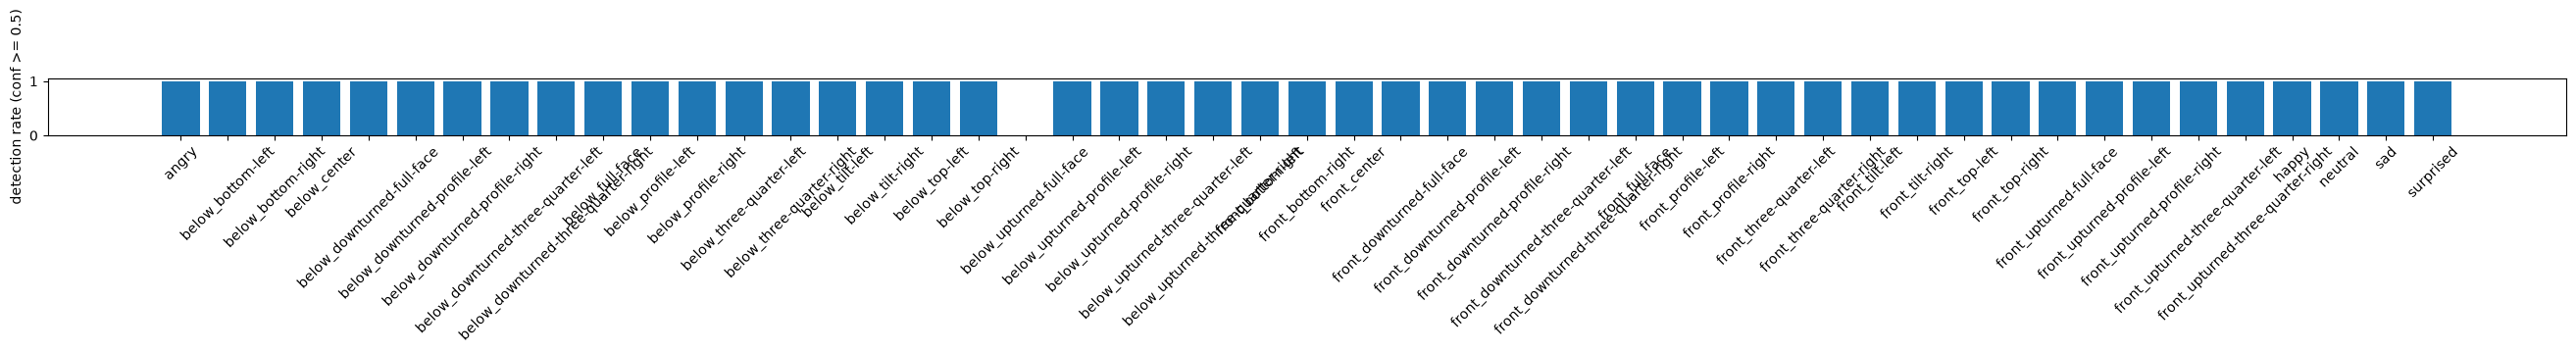

In [9]:
display(plots.detection_rate(out, threshold=DET_THRESHOLD).to_frame())
plots.plot_detection_rate(out, threshold=DET_THRESHOLD);

### Speed (fps on this machine)

Includes video decoding and face detection. Note the hardware (CPU/GPU) in the verdict.

In [10]:
plots.fps_table(timings, out)

,n_frames,seconds,fps
angry,1,0.074351,13.449789
below_bottom-left,1,0.047375,21.107961
below_bottom-right,1,0.060478,16.534846
below_center,1,0.049001,20.407577
below_downturned-full-face,1,0.061911,16.152191
below_downturned-profile-left,1,0.043801,22.830339
below_downturned-profile-right,1,0.045421,22.016153
below_downturned-three-quarter-left,1,0.069055,14.481172
below_downturned-three-quarter-right,1,0.049202,20.324480
below_full-face,1,0.045002,22.221448


### Per-clip summary

One row per clip with mean gaze and head pose over detected frames, next to the manifest's labels. `yaw_error_deg` compares `pose_yaw_deg` with the rough `approx_head_yaw_deg` (0, ±45, ±90) on the head_pose pictures, so treat it as a sanity check, not accuracy.

In [11]:
detected = out[out['face_conf'] >= DET_THRESHOLD]
angle_cols = schema.GAZE_COLUMNS + schema.POSE_COLUMNS
summary = detected.groupby('clip_id').agg(n_frames=('frame', 'size'), face_conf=('face_conf', 'mean'),
                                          **{c: (c, 'mean') for c in angle_cols})
labels = manifest.set_index('clip_id').drop(columns=['path', 'test_set']).dropna(axis=1, how='all')  # skip label columns unused by these categories
summary = labels.join(summary, how='left')
summary['yaw_error_deg'] = summary['pose_yaw_deg'] - summary['approx_head_yaw_deg']
summary.round(1)

,category,camera,gaze_target,expected_emotion,head_yaw,head_pitch,head_roll,approx_head_yaw_deg,n_frames,face_conf,gaze_yaw_deg,gaze_pitch_deg,pose_yaw_deg,pose_pitch_deg,pose_roll_deg,yaw_error_deg
clip_id,,,,,,,,,,,,,,,,
front_center,gaze,front,center,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.6,-1.8,-4.8,0.8,NaN
front_top-left,gaze,front,top-left,NaN,NaN,NaN,NaN,NaN,1.0,1.0,-15.2,-0.5,1.7,-5.3,0.5,NaN
front_top-right,gaze,front,top-right,NaN,NaN,NaN,NaN,NaN,1.0,1.0,15.7,-0.6,-2.8,-4.6,-0.3,NaN
front_bottom-left,gaze,front,bottom-left,NaN,NaN,NaN,NaN,NaN,1.0,1.0,-15.4,10.6,-2.2,-4.9,1.1,NaN
front_bottom-right,gaze,front,bottom-right,NaN,NaN,NaN,NaN,NaN,1.0,1.0,21.1,14.6,-4.6,-5.7,-0.3,NaN
below_center,gaze,below,center,NaN,NaN,NaN,NaN,NaN,1.0,1.0,-0.7,-29.5,0.7,17.4,1.8,NaN
below_top-left,gaze,below,top-left,NaN,NaN,NaN,NaN,NaN,1.0,1.0,-6.2,-35.1,1.7,16.4,2.1,NaN
below_top-right,gaze,below,top-right,NaN,NaN,NaN,NaN,NaN,1.0,1.0,-24.3,-33.0,1.7,18.0,0.7,NaN
below_bottom-left,gaze,below,bottom-left,NaN,NaN,NaN,NaN,NaN,1.0,1.0,-28.9,-17.2,-0.2,17.5,1.8,NaN


In [12]:
# Gaze per target and camera (gaze pictures), and head pose per label and camera (head_pose pictures)
gaze_rows = summary[summary['category'] == 'gaze']
display(gaze_rows.pivot_table(index='gaze_target', columns='camera', values=schema.GAZE_COLUMNS, aggfunc='mean').round(1))
pose_rows = summary[summary['category'] == 'head_pose']
for col in ['head_yaw', 'head_pitch', 'head_roll']:
    display(pose_rows.pivot_table(index=col, columns='camera', values=schema.POSE_COLUMNS, aggfunc='mean').round(1))

gaze_pitch_deg       gaze_yaw_deg      
camera                below front        below front
gaze_target                                         
bottom-left           -17.2  10.6        -28.9 -15.4
bottom-right          -16.5  14.6         -0.7  21.1
center                -29.5   1.6         -0.7   2.0
top-left              -35.1  -0.5         -6.2 -15.2
top-right             -33.0  -0.6        -24.3  15.7

pose_pitch_deg       pose_roll_deg       pose_yaw_deg  \
camera                       below front         below front        below   
head_yaw                                                                    
full-face                     12.9  -0.5           0.3   0.2          4.3   
profile-left                  22.6   2.9          11.6  -2.2         37.6   
profile-right                 25.7   6.6         -16.6  -2.5        -40.0   
three-quarter-left            14.7   0.9           5.3  -2.3         19.6   
three-quarter-right           22.2   3.8         -10.1  -0.7        -22.4   

                           
camera              front  
head_yaw                   
full-face             0.9  
profile-left         52.1  
profile-right       -57.7  
three-quarter-left   26.1  
three-quarter-right -27.6

pose_pitch_deg       pose_roll_deg       pose_yaw_deg      
camera              below front         below front        below front
head_pitch                                                            
downturned            5.2 -17.9          -3.3  -0.9         -1.1   0.2
level                25.6  -0.5           0.8  -1.6          2.4  -1.0
upturned             25.6  26.6          -4.4  -1.3         -2.3  -2.0

pose_pitch_deg       pose_roll_deg       pose_yaw_deg      
camera              below front         below front        below front
head_roll                                                             
none                 18.8   2.4          -1.7  -1.3         -0.7  -0.9
tilt-left            23.2   3.1          13.9  26.1         -0.1   2.7
tilt-right           20.6   0.1         -18.3 -28.6         12.0  -5.8

### AUs and emotions

Mean AU probabilities and emotion probabilities per clip (raw model outputs, not thresholded), next to `expected_emotion` for the emotion pictures. AU columns are ordered by number.

In [13]:
au_cols = [f'extra_{au}_prob' for au in AU_NAMES]
emo_cols = [f'extra_emotion_{e.lower()}' for e in EMOTION_NAMES]
au_table = detected.groupby('clip_id')[au_cols].mean().rename(columns=lambda c: c[len('extra_'):-len('_prob')])
emo_table = detected.groupby('clip_id')[emo_cols + ['extra_valence', 'extra_arousal']].mean().rename(columns=lambda c: c[len('extra_'):].replace('emotion_', ''))
emo_table.insert(0, 'top_emotion', emo_table[[e.lower() for e in EMOTION_NAMES]].idxmax(axis=1))
order = manifest.set_index('clip_id')
emotion_ids = order.index[order['category'] == 'emotion']
display(order.loc[emotion_ids, ['expected_emotion']].join(emo_table).round(2))
display(au_table.reindex(order.index).style.background_gradient(axis=None, vmin=0, vmax=1).format('{:.2f}'))

,expected_emotion,top_emotion,neutral,happy,sad,surprise,fear,disgust,anger,valence,arousal
clip_id,,,,,,,,,,,
neutral,neutral,neutral,0.87,0.01,0.08,0.01,0.01,0.00,0.02,-0.14,-0.07
happy,happy,happy,0.01,0.98,0.00,0.00,0.00,0.00,0.00,0.77,0.08
sad,sad,sad,0.38,0.00,0.59,0.00,0.01,0.00,0.02,-0.38,-0.21
angry,angry,anger,0.03,0.00,0.05,0.00,0.02,0.04,0.86,-0.49,0.59
surprised,surprised,surprise,0.11,0.00,0.01,0.73,0.14,0.00,0.01,0.04,0.57


,AU01,AU02,AU04,AU05,AU06,AU07,AU09,AU10,AU11,AU12,AU14,AU15,AU17,AU20,AU23,AU24,AU25,AU26,AU28,AU43
clip_id,,,,,,,,,,,,,,,,,,,,
front_center,0.04,0.13,0.00,0.05,0.00,0.00,0.01,0.13,0.00,0.04,0.15,0.11,0.06,0.01,0.18,0.51,0.08,0.04,0.05,0.00
front_top-left,0.11,0.13,0.00,0.18,0.00,0.00,0.00,0.11,0.00,0.05,0.09,0.18,0.01,0.00,0.10,0.50,0.09,0.04,0.00,0.00
front_top-right,0.08,0.09,0.00,0.42,0.00,0.00,0.01,0.09,0.00,0.03,0.01,0.17,0.00,0.00,0.07,0.56,0.08,0.04,0.00,0.00
front_bottom-left,0.05,0.19,0.00,0.07,0.00,0.00,0.00,0.17,0.00,0.03,0.10,0.11,0.03,0.03,0.20,0.64,0.02,0.03,0.03,0.01
front_bottom-right,0.09,0.14,0.00,0.09,0.00,0.00,0.00,0.13,0.00,0.04,0.05,0.17,0.01,0.02,0.14,0.43,0.07,0.05,0.03,0.05
below_center,0.22,0.02,0.07,0.10,0.00,0.06,0.00,0.12,0.04,0.02,0.00,0.64,0.00,0.00,0.08,0.77,0.07,0.00,0.06,0.00
below_top-left,0.19,0.05,0.09,0.24,0.00,0.07,0.01,0.19,0.02,0.05,0.00,0.65,0.00,0.00,0.05,0.83,0.07,0.05,0.05,0.00
below_top-right,0.22,0.05,0.05,0.18,0.00,0.14,0.02,0.18,0.08,0.05,0.00,0.66,0.00,0.01,0.05,0.75,0.07,0.03,0.06,0.00
below_bottom-left,0.12,0.05,0.06,0.12,0.00,0.00,0.01,0.05,0.02,0.01,0.00,0.30,0.03,0.00,0.02,0.86,0.05,0.02,0.07,0.00


### Detections on single-image clips

Top face box and confidence on each image, one grid per manifest category, with gaze and head pose drawn from the schema columns (so they also check the sign conversion): red arrow = gaze, blue arrow = where the face points (yaw, pitch), orange line = tilt (roll).

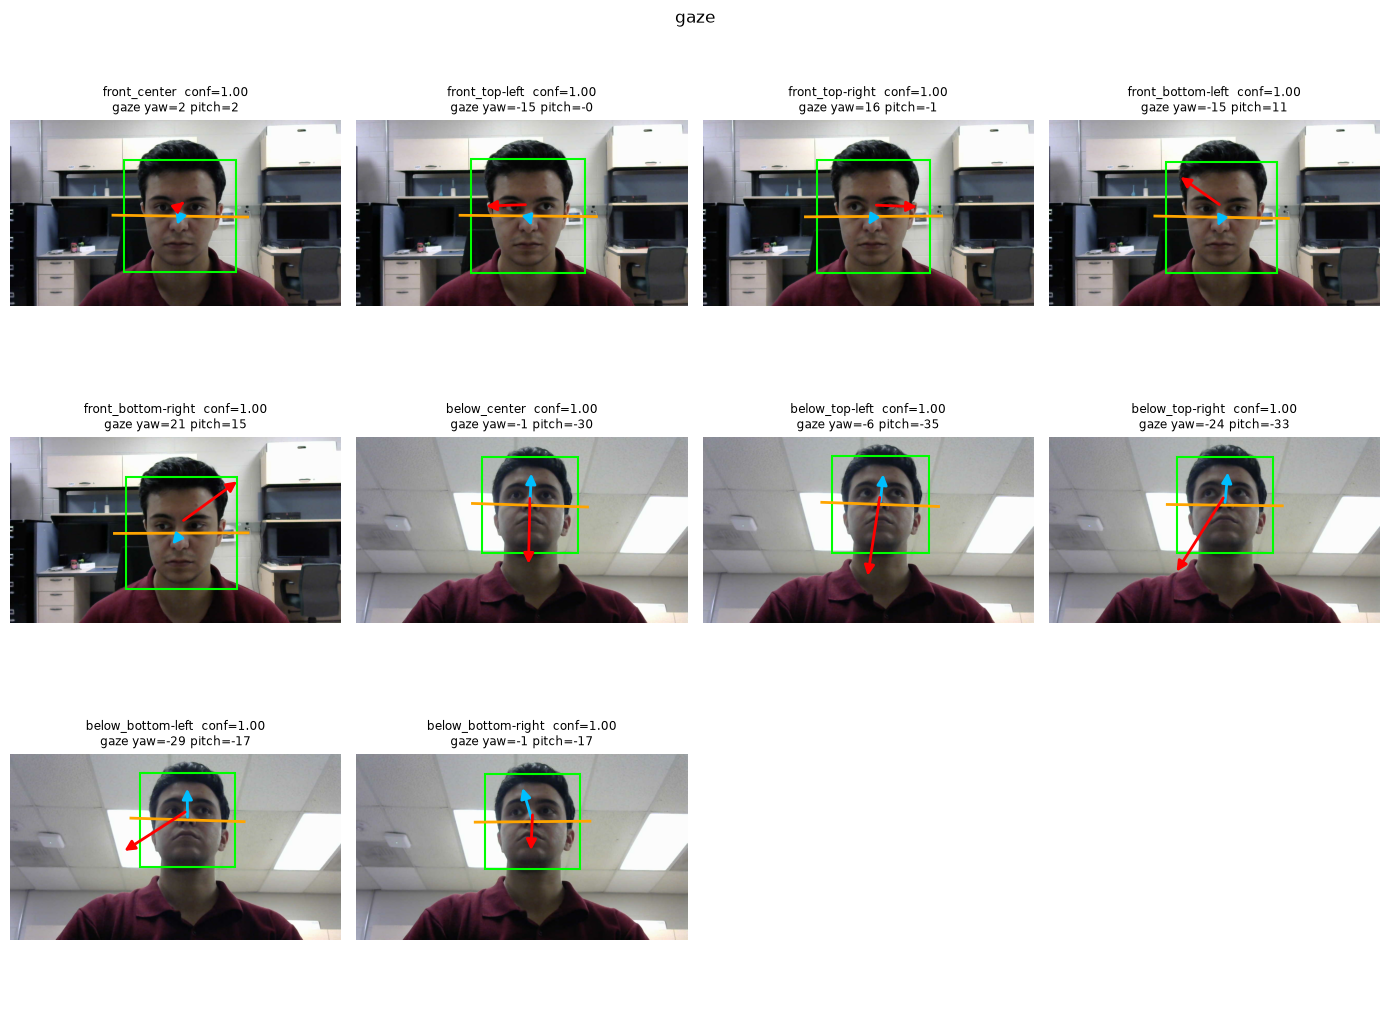

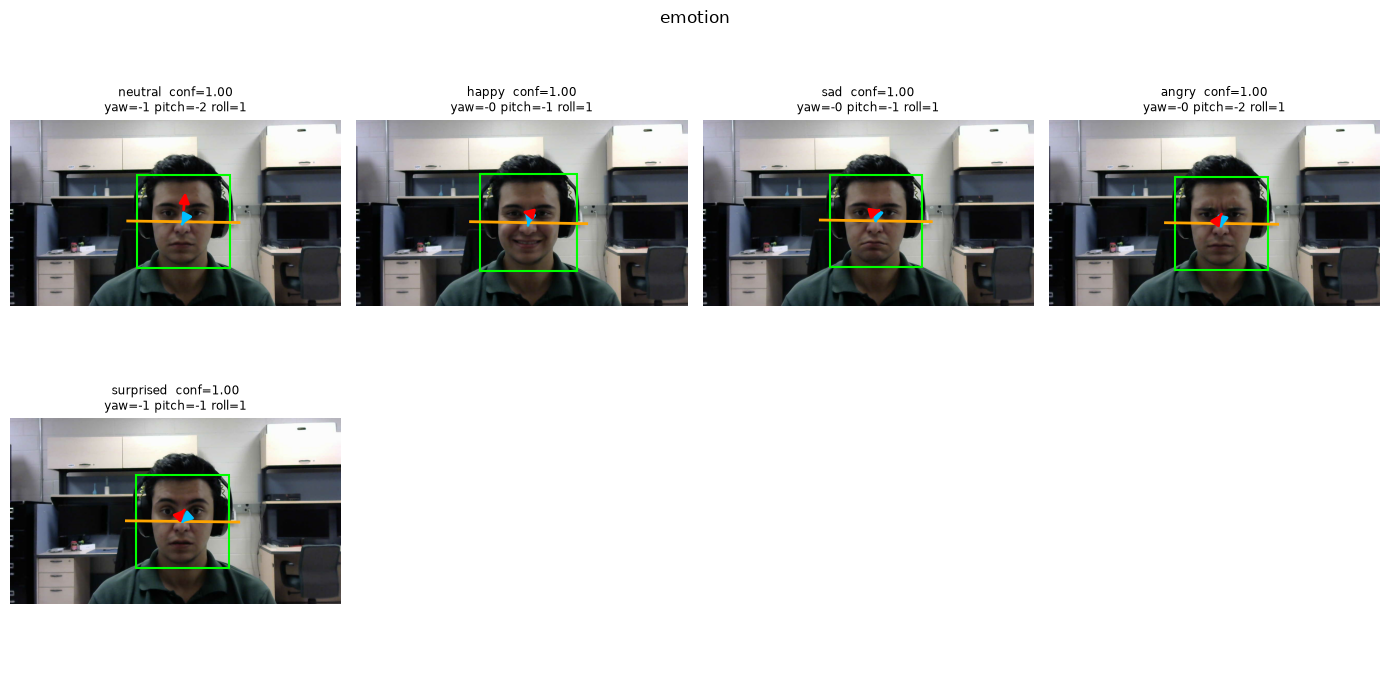

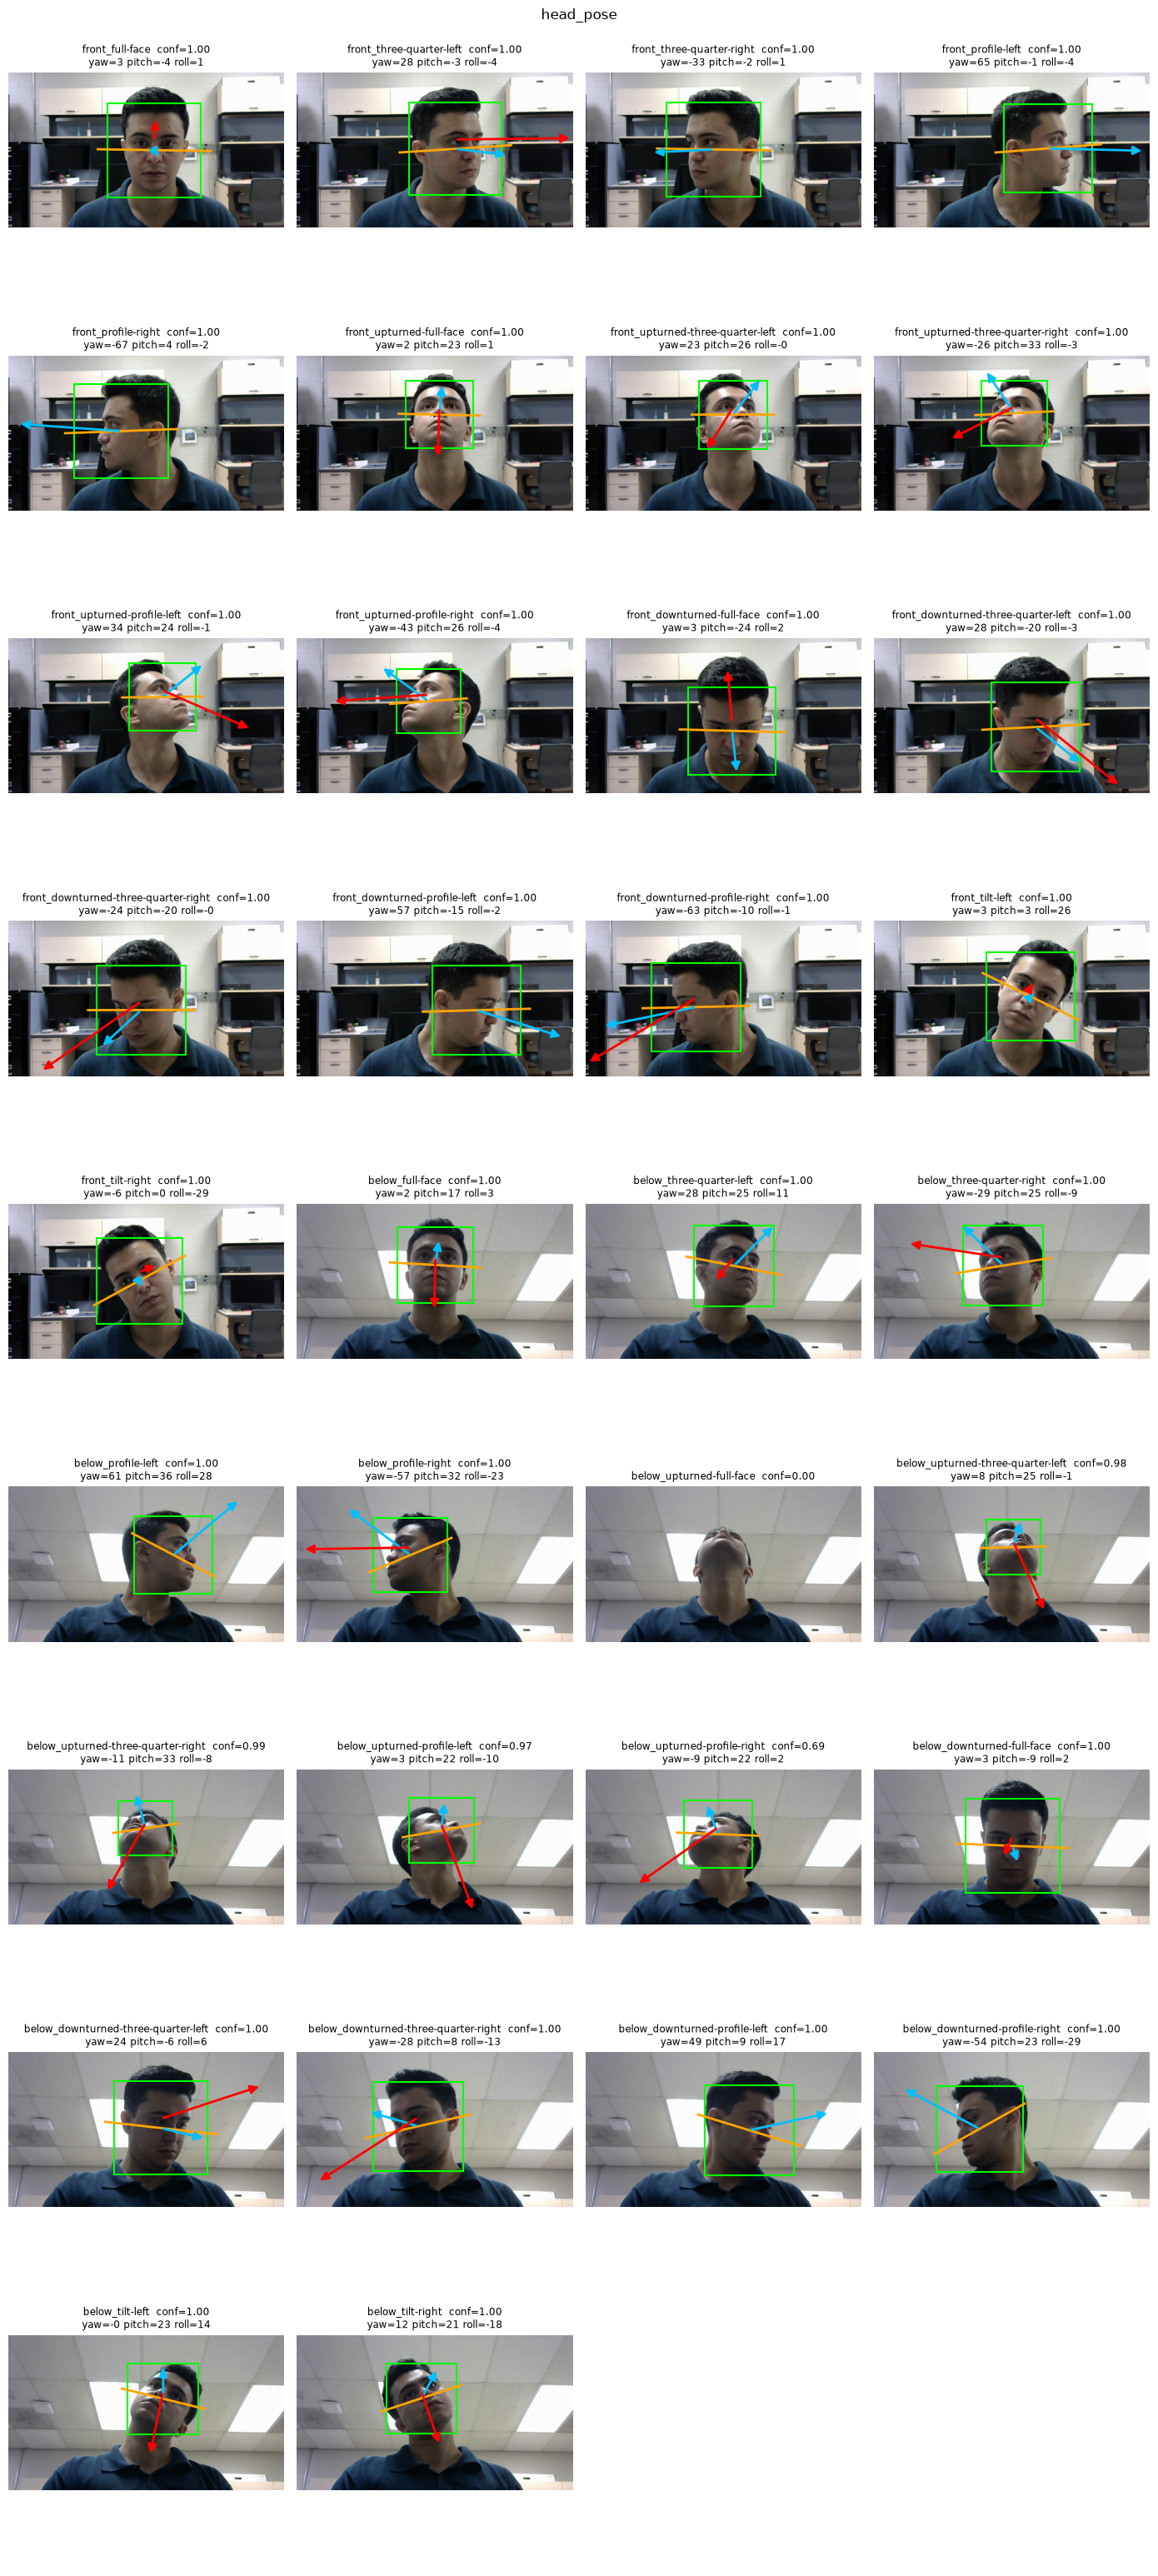

In [14]:
def draw_gaze(ax, r, color='red'):
    """Gaze arrow from roughly eye level, from the schema columns.
    Assumes a true-orientation image: the subject's left is the image's right."""
    if pd.isna(r['gaze_yaw_deg']):
        return
    x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
    cx, cy = (x1 + x2) / 2, y1 + 0.4 * (y2 - y1)
    length = 1.5 * (x2 - x1)
    yaw, pitch = np.radians(r['gaze_yaw_deg']), np.radians(r['gaze_pitch_deg'])
    dx = length * np.sin(yaw) * np.cos(pitch)  # positive yaw (subject's left) -> image right
    dy = -length * np.sin(pitch)               # positive pitch (up) -> image up
    ax.annotate('', xy=(cx + dx, cy + dy), xytext=(cx, cy),
                arrowprops=dict(arrowstyle='-|>', color=color, lw=2, mutation_scale=15))


def draw_pose(ax, r):
    """Face-direction arrow (yaw, pitch) and a roll line from the box centre, from the schema columns."""
    if pd.isna(r['pose_yaw_deg']):
        return
    x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    size = x2 - x1
    yaw, pitch, roll = np.radians(r[['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']].astype(float))
    dx = 1.2 * size * np.sin(yaw) * np.cos(pitch)
    dy = -1.2 * size * np.sin(pitch)
    ax.annotate('', xy=(cx + dx, cy + dy), xytext=(cx, cy),
                arrowprops=dict(arrowstyle='-|>', color='deepskyblue', lw=2, mutation_scale=15))
    # Roll: positive (toward the subject's left shoulder = image right) turns the line clockwise on screen
    lx, ly = 0.6 * size * np.cos(roll), 0.6 * size * np.sin(roll)
    ax.plot([cx - lx, cx + lx], [cy - ly, cy + ly], color='orange', lw=2)


groups = manifest.groupby('category', sort=False) if 'category' in manifest else [('all clips', manifest)]
for category, rows in groups:
    still = [r for r in rows.itertuples() if clip_io.is_image(clip_io.clip_path(r))]
    if not still:
        continue
    ncols = 4
    fig, axes = plt.subplots(-(-len(still) // ncols), ncols, figsize=(3.5 * ncols, 3.5 * -(-len(still) // ncols)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, row in zip(axes.flat, still):
        _, _, img = next(clip_io.iter_frames(clip_io.clip_path(row), rgb=True))
        r = out[out['clip_id'] == row.clip_id].iloc[0]
        ax.imshow(img)
        title = f"{row.clip_id}  conf={r['face_conf']:.2f}"
        if r['face_conf'] >= DET_THRESHOLD:
            x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='lime', lw=1.5))
            draw_pose(ax, r)
            draw_gaze(ax, r)
            if category == 'gaze':
                title += f"\ngaze yaw={r['gaze_yaw_deg']:.0f} pitch={r['gaze_pitch_deg']:.0f}"
            else:
                title += f"\nyaw={r['pose_yaw_deg']:.0f} pitch={r['pose_pitch_deg']:.0f} roll={r['pose_roll_deg']:.0f}"
        ax.set_title(title, fontsize='small')
    fig.suptitle(category)
    plt.tight_layout()
    plt.show()

### Standard plots per clip

Video clips only (time series need more than one frame).

In [15]:
for clip_id, df in out.groupby('clip_id'):
    if len(df) < 2:
        continue
    plots.plot_face_conf(df)
    plots.plot_gaze(df)
    plots.plot_pose(df)
    plt.show()

### Plausibility and stability (no ground truth)

- Value ranges: do the angles look reasonable for what happens in each clip?
- Jitter: median absolute frame-to-frame change on detected frames. A high value on a still face means a noisy model.

In [16]:
display(detected[angle_cols].describe().T.round(3))

# Jitter needs consecutive frames, so only video clips count
multi = detected.groupby('clip_id').filter(lambda d: len(d) > 1)
if len(multi):
    jitter = multi.groupby('clip_id')[angle_cols].apply(lambda d: d.diff().abs().median())
    display(jitter.rename(columns=lambda c: c.replace('_deg', '_jitter_deg')))
else:
    print('no multi-frame clips yet: jitter skipped')

,count,mean,std,min,25%,50%,75%,max
gaze_yaw_deg,48.0,-5.929,53.699,-111.259,-32.822,-0.878,12.756,105.355
gaze_pitch_deg,48.0,-13.155,20.460,-63.355,-29.621,-7.186,1.622,24.396
pose_yaw_deg,48.0,-0.605,28.857,-67.067,-6.553,-0.122,4.159,65.247
pose_pitch_deg,48.0,8.379,16.006,-24.236,-4.464,5.801,22.798,36.139
pose_roll_deg,48.0,-0.801,10.447,-29.298,-2.854,0.584,1.600,27.734


no multi-frame clips yet: jitter skipped


### Failure cases

Frames where the face was missed or detected with low confidence. Look at a few to see why (pose, occlusion, lighting, blur).

In [17]:
failures = plots.failure_frames(out, threshold=DET_THRESHOLD)
display(failures.groupby('clip_id').size().rename('n_failures').to_frame())
failures.head(20)

,n_failures
clip_id,
below_upturned-full-face,1


,clip_id,frame,timestamp_ms,face_conf
18,below_upturned-full-face,0,0.0,0.0


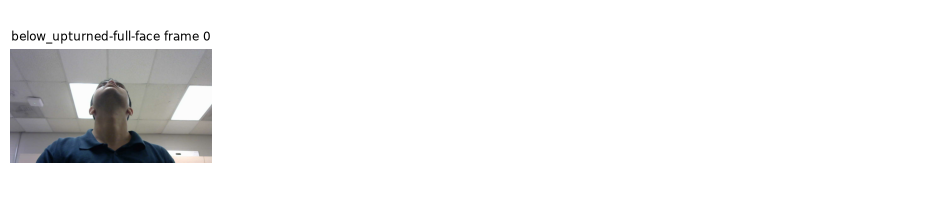

In [18]:
def show_frames(clip_id, frames, ncols=4):
    row = manifest.set_index('clip_id').loc[clip_id]
    wanted = set(frames)
    images = [(f, img) for f, _, img in clip_io.iter_frames(clip_io.clip_path(row), rgb=True) if f in wanted]
    if not images:
        return
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.5 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (f, img) in zip(axes.flat, images):
        ax.imshow(img)
        ax.set_title(f'{clip_id} frame {f}', fontsize='small')
    plt.show()

# Up to 8 evenly spaced failure frames per clip
for clip_id, f in failures.groupby('clip_id'):
    show_frames(clip_id, f['frame'].iloc[np.linspace(0, len(f) - 1, min(8, len(f))).astype(int)])

### Comparison with GazeTR and 6DRepNet

Same pictures, different detector and models. Needs `outputs/GazeTR/` (notebook 03) and `outputs/6DRepNet/` (notebook 05). Differences are in degrees (Py-Feat − other model).

In [19]:
def compare_with(other_model, cols, category):
    ids = manifest.loc[manifest['category'] == category, 'clip_id']
    other = clip_io.load_outputs(other_model, ids)
    both = (out.set_index('clip_id').loc[ids, ['face_conf'] + cols]
            .join(other.set_index('clip_id')[['face_conf'] + cols], lsuffix=f'_{MODEL}', rsuffix=f'_{other_model}'))
    for c in cols:
        both[c.replace('_deg', '_diff_deg')] = both[f'{c}_{MODEL}'] - both[f'{c}_{other_model}']
    keep = [c for c in ['camera', 'gaze_target', 'head_yaw', 'head_pitch', 'head_roll', 'approx_head_yaw_deg']
            if manifest.loc[manifest['category'] == category, c].notna().any()]
    table = manifest.set_index('clip_id').loc[ids, keep].join(both)
    display(table.round(1))
    display(table[[c.replace('_deg', '_diff_deg') for c in cols]].abs().describe().round(1))
    return table


gaze_compare = compare_with('GazeTR', schema.GAZE_COLUMNS, 'gaze')
pose_compare = compare_with('6DRepNet', schema.POSE_COLUMNS, 'head_pose')

,camera,gaze_target,face_conf_Py-Feat,gaze_yaw_deg_Py-Feat,gaze_pitch_deg_Py-Feat,face_conf_GazeTR,gaze_yaw_deg_GazeTR,gaze_pitch_deg_GazeTR,gaze_yaw_diff_deg,gaze_pitch_diff_deg
clip_id,,,,,,,,,,
front_center,front,center,1.0,2.0,1.6,0.9,-11.2,-23.9,13.1,25.5
front_top-left,front,top-left,1.0,-15.2,-0.5,0.9,22.3,-4.7,-37.5,4.2
front_top-right,front,top-right,1.0,15.7,-0.6,0.9,-39.2,-11.8,55.0,11.2
front_bottom-left,front,bottom-left,1.0,-15.4,10.6,0.9,25.4,-30.7,-40.8,41.3
front_bottom-right,front,bottom-right,1.0,21.1,14.6,0.9,-36.9,-28.6,57.9,43.3
below_center,below,center,1.0,-0.7,-29.5,0.9,5.0,33.4,-5.7,-62.9
below_top-left,below,top-left,1.0,-6.2,-35.1,0.9,32.0,40.6,-38.2,-75.7
below_top-right,below,top-right,1.0,-24.3,-33.0,0.9,-36.1,39.8,11.7,-72.8
below_bottom-left,below,bottom-left,1.0,-28.9,-17.2,0.9,34.7,21.8,-63.6,-39.1


,gaze_yaw_diff_deg,gaze_pitch_diff_deg
count,10.0,10.0
mean,35.4,41.8
std,20.2,24.0
min,5.7,4.2
25%,17.4,28.9
50%,37.8,41.7
75%,51.4,58.0
max,63.6,75.7


,camera,head_yaw,head_pitch,head_roll,approx_head_yaw_deg,face_conf_Py-Feat,pose_yaw_deg_Py-Feat,pose_pitch_deg_Py-Feat,pose_roll_deg_Py-Feat,face_conf_6DRepNet,pose_yaw_deg_6DRepNet,pose_pitch_deg_6DRepNet,pose_roll_deg_6DRepNet,pose_yaw_diff_deg,pose_pitch_diff_deg,pose_roll_diff_deg
clip_id,,,,,,,,,,,,,,,,
front_full-face,front,full-face,level,none,0.0,1.0,2.7,-4.4,0.9,0.9,0.1,-8.8,1.3,2.6,4.3,-0.5
front_three-quarter-left,front,three-quarter-left,level,none,45.0,1.0,28.3,-3.2,-3.7,0.9,37.8,-4.3,0.9,-9.5,1.0,-4.7
front_three-quarter-right,front,three-quarter-right,level,none,-45.0,1.0,-33.2,-1.5,0.9,0.9,-46.4,-6.4,-6.9,13.2,4.9,7.8
front_profile-left,front,profile-left,level,none,90.0,1.0,65.2,-1.3,-4.5,0.9,76.4,2.9,1.1,-11.1,-4.2,-5.6
front_profile-right,front,profile-right,level,none,-90.0,1.0,-67.1,3.7,-2.1,0.9,-75.3,-8.4,-12.9,8.2,12.1,10.8
front_upturned-full-face,front,full-face,upturned,none,0.0,1.0,2.3,22.7,1.2,0.9,-1.4,32.4,-0.7,3.7,-9.7,1.9
front_upturned-three-quarter-left,front,three-quarter-left,upturned,none,45.0,1.0,22.6,26.1,-0.0,0.9,18.8,31.0,-11.3,3.7,-4.8,11.3
front_upturned-three-quarter-right,front,three-quarter-right,upturned,none,-45.0,1.0,-26.0,33.1,-2.8,0.9,-22.2,36.4,11.0,-3.8,-3.3,-13.9
front_upturned-profile-left,front,profile-left,upturned,none,90.0,1.0,34.1,24.4,-0.7,0.9,41.2,42.7,-32.4,-7.1,-18.3,31.7


,pose_yaw_diff_deg,pose_pitch_diff_deg,pose_roll_diff_deg
count,30.0,30.0,30.0
mean,6.5,10.2,11.8
std,5.9,8.6,11.7
min,0.3,1.0,0.0
25%,2.8,4.2,1.5
50%,4.9,8.1,10.3
75%,8.4,12.0,13.8
max,31.5,29.8,37.8
